# 02. 데이터 전처리

`01_collect.ipynb`에서 수집한 원본(`data/raw/steam_reviews_ko_raw.csv`)을 정제해 라벨링·학습용 데이터셋을 만든다.

| 단계 | 기법 | 목적 |
|---|---|---|
| ① | **마크업 제거** — BBCode(`[h1]`, `[spoiler]`), HTML 태그, URL | 모델이 의미 없는 토큰을 학습하지 않도록 |
| ② | **문자 정규화** — 유니코드 NFC, 아스키아트·이모지 제거, 반복 문자 축약(`ㅋㅋㅋㅋ→ㅋㅋ`, `!!!!→!!`), 공백 정리 | 같은 표현을 같은 입력으로, 시퀀스 길이 절약 |
| ③ | **중복 제거** — 공백·문장부호를 무시한 정규화 키 기준 | "good", "갓겜" 같은 복붙 리뷰의 과대표집 방지 |
| ④ | **언어 필터** — 한글 비율(한글/(한글+영문)) < 0.5 제거 | 한국어 모델 대상, 영어·무의미 문자열 제거 |
| ⑤ | **길이 필터** — 15자 미만 / 2,000자 초과 제거 | 속성 정보가 없는 초단문, 극단적 장문 이상치 제거 |

정제 함수는 `src/preprocess.py`에 두고 **서비스 앱에서도 같은 함수를 사용**한다(학습·추론 입력 일치).

**산출물:** `data/processed/reviews_clean.csv`, `figures/02_*.png`

In [1]:
# ── 환경 설정 ────────────────────────────────────────────
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")       # Drive 연결 위치(수정 X)

# ▶ 프로젝트 폴더 경로 (01 노트북과 동일하게)
def find_root():
    """프로젝트 폴더 자동 탐색. Drive의 한글 폴더명이 NFD(자모 분리)로 저장되면
    "ML 기말" 같은 문자열 경로가 일치하지 않으므로, MyDrive를 직접 훑어
    data/processed/reviews_clean.csv가 있는 폴더를 찾는다(검수 파일이 있는 쪽 우선)."""
    if os.environ.get("ML_ROOT"):
        return Path(os.environ["ML_ROOT"])
    base = Path("/content/drive/MyDrive")
    cands = [p for p in [base, *base.glob("*"), *base.glob("*/*")]
             if p.is_dir() and (p / "data" / "processed" / "reviews_clean.csv").exists()]
    if not cands:
        print("⚠ 프로젝트 폴더를 찾지 못해 기본 경로를 사용합니다.")
        return base / "ML 기말"
    cands.sort(key=lambda p: not (p / "data" / "labeling" / "test_verify.csv").exists())
    if len(cands) > 1:
        print("⚠ 프로젝트 폴더 후보가 여러 개입니다 → 첫 번째 사용:", *cands, sep="\n   ")
    return cands[0]

ROOT = find_root()
sys.path.append(str(ROOT / "src"))      # src/preprocess.py 등 공용 모듈
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT, "| exists:", ROOT.exists())

Mounted at /content/drive
ROOT: /content/drive/MyDrive/머신러닝 포트폴리오 | exists: True


In [2]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from preprocess import clean_text, remove_markup, normalize_chars, hangul_ratio, dedup_key

MIN_LEN, MAX_LEN = 15, 2000          # ⑤ 길이 필터(정제 후 글자 수)
MIN_HANGUL_RATIO = 0.5               # ④ 언어 필터

raw = pd.read_csv(ROOT / "data" / "raw" / "steam_reviews_ko_raw.csv",
                  dtype={"recommendationid": str})
raw["review"] = raw["review"].fillna("").astype(str)
raw["len_raw"] = raw["review"].str.len()
print(f"원본: {len(raw):,}건, 게임 {raw['game'].nunique()}종")

원본: 14,909건, 게임 16종


## 1. 전처리 전 상태 진단

정제 기준을 정하기 위해 원본에 어떤 문제가 얼마나 있는지 먼저 센다.

In [3]:
def count(pattern, s=raw["review"]):
    rx = re.compile(pattern)
    return int(s.map(lambda t: bool(rx.search(t))).sum())

diag = pd.DataFrame([
    ("BBCode 태그 포함",            count(r"\[/?[a-zA-Z0-9*]{1,10}(?:=[^\]]{0,200})?\]")),
    ("HTML 태그 포함",              count(r"<[^>]{1,100}>")),
    ("URL 포함",                    count(r"https?://|www\.")),
    ("같은 문자 3회 이상 반복",       count(r"([^\d\s])\1{2,}")),
    ("줄바꿈 포함",                  count(r"[\r\n]")),
    ("아스키아트·이모지 포함",        count("[\u2500-\u25FF\U0001F000-\U0001FAFF]")),
    ("완전히 같은 문장(중복)",        int(raw["review"].duplicated().sum())),
    ("한글 비율 < 0.5",              int((raw["review"].map(hangul_ratio) < MIN_HANGUL_RATIO).sum())),
    (f"{MIN_LEN}자 미만",            int((raw["len_raw"] < MIN_LEN).sum())),
    (f"{MAX_LEN}자 초과",            int((raw["len_raw"] > MAX_LEN).sum())),
], columns=["문제 유형", "건수"])
diag["비율"] = (diag["건수"] / len(raw)).map("{:.1%}".format)
diag

,문제 유형,건수,비율
0,BBCode 태그 포함,126,0.8%
1,HTML 태그 포함,19,0.1%
2,URL 포함,15,0.1%
3,같은 문자 3회 이상 반복,1853,12.4%
4,줄바꿈 포함,5079,34.1%
5,아스키아트·이모지 포함,69,0.5%
6,완전히 같은 문장(중복),802,5.4%
7,한글 비율 < 0.5,977,6.6%
8,15자 미만,3249,21.8%
9,2000자 초과,41,0.3%


In [4]:
# 가장 많이 중복된 리뷰 Top 10
raw["review"].str.strip().value_counts().head(10).rename("중복 횟수").to_frame()

,중복 횟수
review,
good,141
갓겜,74
재밌음,69
굿,37
재밌어요,35
.,33
재밌다,25
good game,20
굳,19


## 2. 단계별 정제

In [5]:
df = raw.copy()
log = [("원본", len(df))]

# ① 마크업 제거 ─────────────────────────────
df["step1"] = df["review"].map(remove_markup)

# ② 문자 정규화 ─────────────────────────────
df["text"] = df["step1"].map(normalize_chars)
assert (df["text"] == df["review"].map(clean_text)).all()   # 파이프라인 일치 확인
df["len_clean"] = df["text"].str.len()
print(f"①② 정제 후 평균 길이: {df['len_raw'].mean():.1f} → {df['len_clean'].mean():.1f}자")

# ③ 중복 제거 ──────────────────────────────
df["dkey"] = df["text"].map(dedup_key)
df = df[df["dkey"] != ""]
df = df.drop_duplicates("dkey", keep="first")
log.append(("③ 중복 제거", len(df)))

# ④ 언어 필터 ──────────────────────────────
df["hangul_ratio"] = df["text"].map(hangul_ratio)
df = df[df["hangul_ratio"] >= MIN_HANGUL_RATIO]
log.append(("④ 언어 필터(한글 비율)", len(df)))

# ⑤ 길이 필터 ──────────────────────────────
df = df[(df["len_clean"] >= MIN_LEN) & (df["len_clean"] <= MAX_LEN)]
log.append(("⑤ 길이 필터", len(df)))

df = df.reset_index(drop=True)
log_df = pd.DataFrame(log, columns=["단계", "남은 건수"])
log_df["제거"] = (-log_df["남은 건수"].diff()).fillna(0).astype(int)
log_df["원본 대비"] = (log_df["남은 건수"] / len(raw)).map("{:.1%}".format)
log_df

①② 정제 후 평균 길이: 95.1 → 92.6자


,단계,남은 건수,제거,원본 대비
0,원본,14909,0,100.0%
1,③ 중복 제거,13847,1062,92.9%
2,④ 언어 필터(한글 비율),13290,557,89.1%
3,⑤ 길이 필터,11177,2113,75.0%


## 3. 전처리 전·후 비교

In [6]:
# 정제로 텍스트가 실제로 바뀐 사례
changed = df[df["review"].str.strip() != df["text"]]
print(f"①② 단계에서 내용이 바뀐 리뷰: {len(changed):,}건 ({len(changed)/len(df):.1%})\n")

def show(mask, title, n=2):
    sub = changed[mask(changed)].head(n)
    for _, r in sub.iterrows():
        print(f"■ {title}")
        print("  전:", repr(r["review"][:150]))
        print("  후:", repr(r["text"][:150]))
        print()

show(lambda d: d["review"].str.contains(r"\[/?[a-z0-9]{1,10}\]", regex=True), "BBCode 제거")
show(lambda d: d["review"].map(lambda t: bool(re.search(r"([ㅋㅎㅠㅜ!?.])\1{3,}", t))), "반복 문자 축약")
show(lambda d: d["review"].str.contains(r"https?://", regex=True), "URL 제거", n=1)

①② 단계에서 내용이 바뀐 리뷰: 5,228건 (46.8%)

■ BBCode 제거
  전: '[h2][b]🏆도전과제 100% 달성 완료[/b][/h2]\n[b] 근 10년간 이런 저런 말 참 많았지만 \n친구들과 함께 가장 대중적으로 재밌게 즐길 수 있는\n몇 안되는 배틀로얄/FPS 장르 GOAT [/b]'
  후: '도전과제 100% 달성 완료 근 10년간 이런 저런 말 참 많았지만 친구들과 함께 가장 대중적으로 재밌게 즐길 수 있는 몇 안되는 배틀로얄/FPS 장르 GOAT'

■ BBCode 제거
  전: '어.. 일단 이 게임이 재밌기는 해요.\r\n근데 제가 모바일 배틀그라운드를 하다가 와서 그런지 모르겠지만\r\n같은 레벨? 실력대랑 매칭이 안되요.\r\n제 경험담인데 첫판에 250렙 만나서 죽었거든요?\r\n그래서 뭔가 잘 못하면 약간 비추입니다.\r\n[strike]진짜 이거 좀 '
  후: '어.. 일단 이 게임이 재밌기는 해요. 근데 제가 모바일 배틀그라운드를 하다가 와서 그런지 모르겠지만 같은 레벨? 실력대랑 매칭이 안되요. 제 경험담인데 첫판에 250렙 만나서 죽었거든요? 그래서 뭔가 잘 못하면 약간 비추입니다. 진짜 이거 좀 고쳐라 크래프톤'

■ 반복 문자 축약
  전: '아니 겜을 한적이 없는데 영정당해있음 머임? 진짜 옜날에 하고 한번을 안했는데 개 얼탱이 없네 ㅋㅋㅋㅋ'
  후: '아니 겜을 한적이 없는데 영정당해있음 머임? 진짜 옜날에 하고 한번을 안했는데 개 얼탱이 없네 ㅋㅋ'

■ 반복 문자 축약
  전: '서든 이후 최고의 fps 명작게임이긴 했네요\nai 엔진 기대합니다만.......실현 가능성은 글쎄,,,,,'
  후: '서든 이후 최고의 fps 명작게임이긴 했네요 ai 엔진 기대합니다만..실현 가능성은 글쎄,,'

■ URL 제거
  전: '♚♚배틀☆그라운드♚♚\n접속시$$전원 프라이팬☜☜100%필드증정※ ♜이겼닭! 오늘 저녁은 치킨이닭!♜매 게임 무료 보급 증정 이벤트￥ 특정조건 §§3레벨 헬멧§§★길리슈트★획득기회

In [7]:
# 정량 비교표
def stats(frame, col_text, col_len):
    return {
        "리뷰 수": len(frame),
        "평균 길이(자)": round(frame[col_len].mean(), 1),
        "중앙값 길이(자)": frame[col_len].median(),
        "추천 비율": round(frame["voted_up"].mean(), 3),
        "중복 문장 수": int(frame[col_text].duplicated().sum()),
        "BBCode 포함": int(frame[col_text].str.contains(r"\[/?[a-z0-9]{1,10}\]", regex=True).sum()),
    }

compare = pd.DataFrame({"전처리 전": stats(raw, "review", "len_raw"),
                        "전처리 후": stats(df, "text", "len_clean")})
compare

,전처리 전,전처리 후
리뷰 수,14909.000,11177.000
평균 길이(자),95.100,105.600
중앙값 길이(자),41.000,53.000
추천 비율,0.848,0.833
중복 문장 수,802.000,0.000
BBCode 포함,126.000,0.000


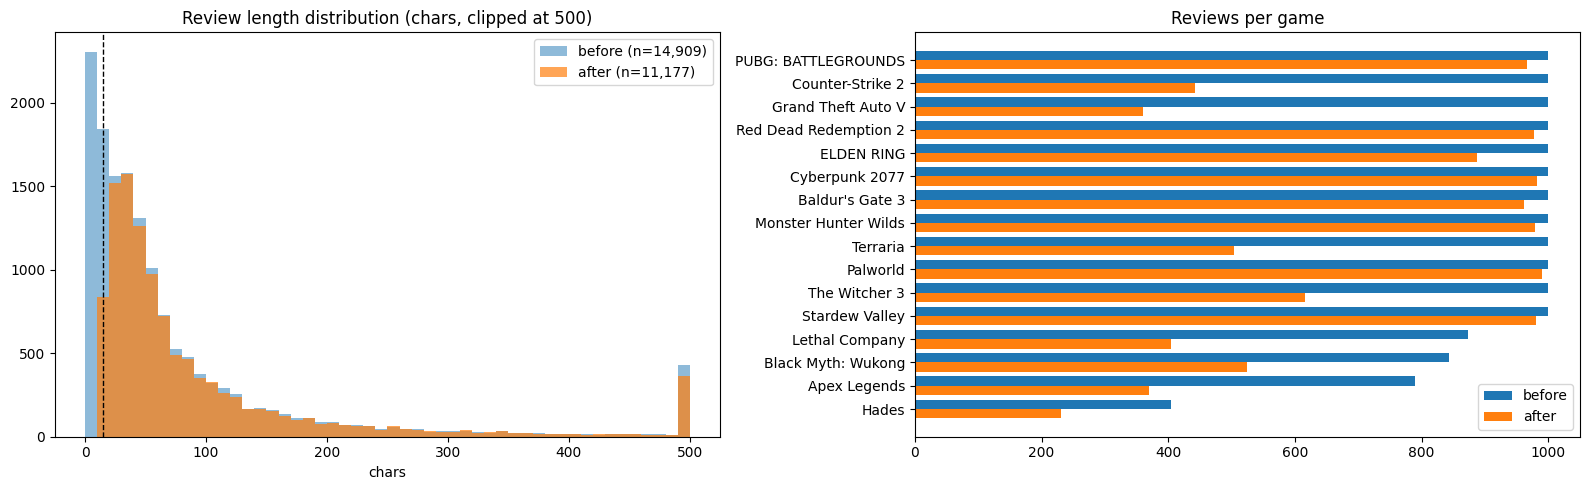

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bins = np.linspace(0, 500, 51)
axes[0].hist(raw["len_raw"].clip(upper=500), bins=bins, alpha=0.5, label=f"before (n={len(raw):,})")
axes[0].hist(df["len_clean"].clip(upper=500), bins=bins, alpha=0.7, label=f"after (n={len(df):,})")
axes[0].axvline(MIN_LEN, color="k", ls="--", lw=1)
axes[0].set_title("Review length distribution (chars, clipped at 500)")
axes[0].set_xlabel("chars"); axes[0].legend()

before = raw["game"].value_counts()
after = df["game"].value_counts().reindex(before.index).fillna(0)
y = np.arange(len(before))
axes[1].barh(y - 0.2, before.values, height=0.4, label="before")
axes[1].barh(y + 0.2, after.values, height=0.4, label="after")
axes[1].set_yticks(y); axes[1].set_yticklabels(before.index); axes[1].invert_yaxis()
axes[1].set_title("Reviews per game"); axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "02_preprocess_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# 게임별 잔존율·추천 비율
per_game = pd.DataFrame({
    "전": raw["game"].value_counts(),
    "후": df["game"].value_counts(),
}).fillna(0).astype(int)
per_game["잔존율"] = (per_game["후"] / per_game["전"]).round(3)
per_game["추천 비율(후)"] = df.groupby("game")["voted_up"].mean().round(3)
per_game.sort_values("후", ascending=False)

,전,후,잔존율,추천 비율(후)
game,,,,
Palworld,1000,990,0.990,0.919
Cyberpunk 2077,1000,982,0.982,0.896
Stardew Valley,1000,981,0.981,0.966
Monster Hunter Wilds,1000,979,0.979,0.557
Red Dead Redemption 2,1000,977,0.977,0.879
PUBG: BATTLEGROUNDS,1000,966,0.966,0.607
Baldur's Gate 3,1000,962,0.962,0.926
ELDEN RING,1000,888,0.888,0.899
The Witcher 3,1000,616,0.616,0.841


## 4. 저장

In [10]:
KEEP = ["recommendationid", "appid", "game", "genre", "text", "len_clean", "voted_up",
        "votes_up", "weighted_vote_score", "playtime_at_review", "playtime_forever",
        "written_during_early_access", "timestamp_created"]
out = df[KEEP].rename(columns={"len_clean": "length"})

OUT = ROOT / "data" / "processed" / "reviews_clean.csv"
OUT.parent.mkdir(parents=True, exist_ok=True)
out.to_csv(OUT, index=False, encoding="utf-8-sig")
print(f"저장: {OUT}  ({len(out):,}건)")
out.sample(5, random_state=42)[["game", "voted_up", "length", "text"]]

저장: /content/drive/MyDrive/머신러닝 포트폴리오/data/processed/reviews_clean.csv  (11,177건)


,game,voted_up,length,text
9638,Palworld,True,169,"전투, 수집, 건축 중 둘 이상 흥미 있으면 ㄱㄱ 도전과제 올클 할려면 투기장 10..."
10686,Lethal Company,False,47,업데이트 되고나서 멀미유발이 너무 심하네요.. 행성간의 로딩도 너무 길어져서 별로에요
7021,Baldur's Gate 3,True,31,"소매치기만 하고 다니다 보니, 현실에서도 하고 싶어요.."
5729,Monster Hunter Wilds,True,243,아직도 씨발 니가와라 에겐 공룡 권법은 버리지 않았구나? 수틀리면 몸부림 존나 치고...
7231,Baldur's Gate 3,True,21,보스를 잡지 않고 엔딩 볼수 있는 게임


## 정리

- 전처리 로그 표(단계별 제거 건수)와 전·후 비교표·그래프는 README `## 3. 데이터 전처리`에 사용한다.
- 다음 단계: 정제 데이터에서 라벨링 대상 2,000건을 샘플링 → 속성 8개 × {미언급, 긍정, 보통, 부정} 라벨 부여